# Mu Ramp Analysis: Order Parameter and Structure Factor

Analyzes simulations where the Maier-Saupe interaction strength **μ** is linearly ramped between 0 and 50:
- **Order parameter** (λ = `LambdaMaierSaupe0`) vs μ for all LC lengths and both ramp directions
- **Structure factor** S(q) vs wavevector |q|, computed via 3-D FFT of density fields

## Data sources
| Type | Path |
|------|------|
| Log files | `/home/gabriel/Projects/Mu_ramp/Logs/` |
| Density binaries | `/home/gabriel/Projects/Mu_ramp/Density/Mu_ramp_Nb_*/` |

## Binary format (density files)
**Header (once):** `Dim` (i32), `Nx[Dim]` (i32×Dim), `L[Dim]` (f32×Dim), `ntypes` (i32)  
**Per frame:** `ρ[ntypes × M]` (f32), where M = Nx[0]×Nx[1]×Nx[2]

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
import pandas as pd
import os
import re
from glob import glob
from tqdm.notebook import tqdm

## Configuration

In [24]:
# --- Paths ---
LOG_DIR     = "/home/gabriel/Projects/Mu_ramp/Logs"
DENSITY_DIR = "/home/gabriel/Projects/Mu_ramp/Density"
OUTPUT_DIR  = "/home/gabriel/Projects/Mu_ramp"

# --- Ramp parameters ---
MU_MAX = 50.0          # Max μ value at the peak of the ramp

# --- S(k) settings ---
DENSITY_TYPE = 0       # Particle type index (0 = first type)
SK_N_BINS    = 100      # Radial bins for S(q) averaging

# Target μ values to compare in per-LC-length S(q) plots
TARGET_MU = [1, 10, 25, 50]

# --- Filename patterns ---
LOG_RE = re.compile(r"(increasing|decreasing)_Mu_ramp_LC_length_(\d+)_rep_(\d+)\.dat")
DEN_RE = re.compile(r"(increasing|decreasing)_Mu_ramp_LC_length_(\d+)_rep_(\d+)_den\.bin")

---
## Part 1 — Order Parameter Analysis
### Load log files

In [15]:
COLS = [
    'step', 'global_step', 'Upe', 'Ubond', 'Angles',
    'Pxx', 'Pyy', 'Pzz', 'Pxy', 'Pxz', 'Pyz',
    'Gaussian0', 'MaierSaupe0', 'LambdaMaierSaupe0', 'UDBond'
]

def read_log(filepath):
    """Read a MATILDA.FT .dat log file into a DataFrame."""
    return pd.read_csv(filepath, sep=r'\s+', comment='#', header=None, names=COLS)


log_files = sorted(glob(os.path.join(LOG_DIR, "*.dat")))
print(f"Found {len(log_files)} log files:")
for f in log_files:
    print(f"  {os.path.basename(f)}")

records = []
for fp in log_files:
    m = LOG_RE.match(os.path.basename(fp))
    if not m:
        print(f"  Warning: could not parse '{os.path.basename(fp)}', skipping.")
        continue
    direction = m.group(1)
    nb        = int(m.group(2))
    rep       = int(m.group(3))

    df = read_log(fp)
    max_step = df['step'].max()

    # Map simulation step → μ
    if direction == 'increasing':
        df['mu'] = df['step'] / max_step * MU_MAX
    else:
        df['mu'] = MU_MAX * (1.0 - df['step'] / max_step)

    df['direction'] = direction
    df['nb']        = nb
    df['rep']       = rep
    records.append(df)

all_logs = pd.concat(records, ignore_index=True)
nb_values = sorted(all_logs['nb'].unique())
print(f"\nLC lengths: {nb_values}")
print(f"Total log rows: {len(all_logs)}")

Found 10 log files:
  decreasing_Mu_ramp_LC_length_12_rep_0.dat
  decreasing_Mu_ramp_LC_length_15_rep_0.dat
  decreasing_Mu_ramp_LC_length_3_rep_0.dat
  decreasing_Mu_ramp_LC_length_6_rep_0.dat
  decreasing_Mu_ramp_LC_length_9_rep_0.dat
  increasing_Mu_ramp_LC_length_12_rep_0.dat
  increasing_Mu_ramp_LC_length_15_rep_0.dat
  increasing_Mu_ramp_LC_length_3_rep_0.dat
  increasing_Mu_ramp_LC_length_6_rep_0.dat
  increasing_Mu_ramp_LC_length_9_rep_0.dat

LC lengths: [3, 6, 9, 12, 15]
Total log rows: 5000


### Plot: order parameter λ vs μ — all LC lengths

/tmp/ipykernel_2021633/193594639.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap      = plt.cm.get_cmap('tab10', len(nb_values))


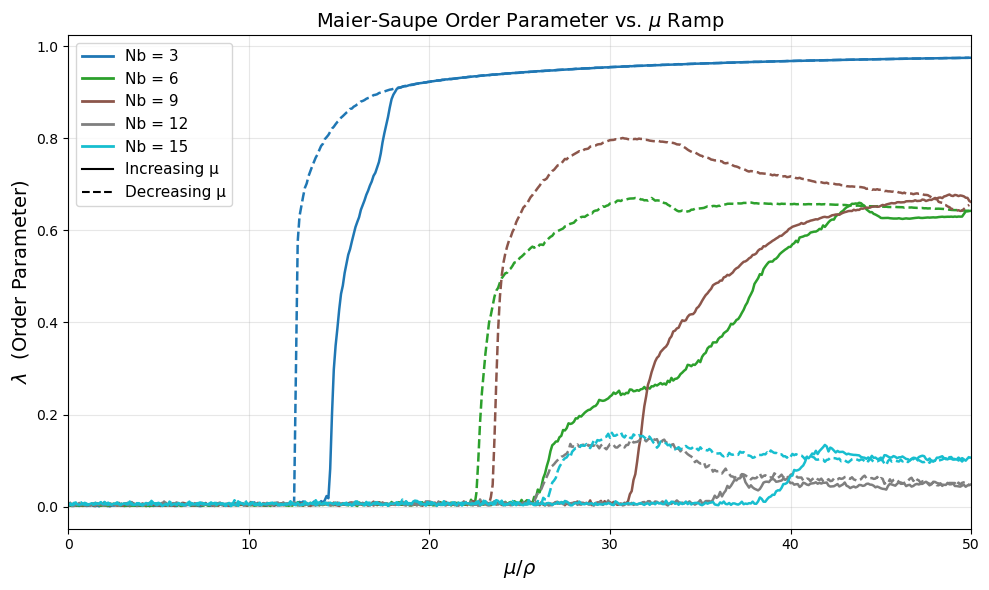

In [16]:
cmap      = plt.cm.get_cmap('tab10', len(nb_values))
nb_colors = {nb: cmap(i) for i, nb in enumerate(nb_values)}
ls_map    = {'increasing': '-', 'decreasing': '--'}

fig, ax = plt.subplots(figsize=(10, 6))

for (nb, direction), grp in all_logs.groupby(['nb', 'direction']):
    grp = grp.sort_values('mu')
    ax.plot(
        grp['mu'], grp['LambdaMaierSaupe0'],
        color=nb_colors[nb], linestyle=ls_map[direction], lw=1.8
    )

# Legend: Nb by colour, direction by line style
legend_elems  = [Line2D([0],[0], color=nb_colors[nb], lw=2, label=f"Nb = {nb}")
                 for nb in nb_values]
legend_elems += [
    Line2D([0],[0], color='k', lw=1.5, ls='-',  label='Increasing μ'),
    Line2D([0],[0], color='k', lw=1.5, ls='--', label='Decreasing μ'),
]
ax.legend(handles=legend_elems, fontsize=11, loc='upper left')

ax.set_xlabel(r"$\mu / \rho$",                fontsize=14)
ax.set_ylabel(r"$\lambda$  (Order Parameter)", fontsize=14)
ax.set_title( r"Maier-Saupe Order Parameter vs. $\mu$ Ramp", fontsize=14)
ax.set_xlim(0, MU_MAX)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "order_parameter_vs_mu.png"), dpi=150)
plt.show()

---
## Part 2 — Structure Factor S(q)

Reads density binary files and computes S(q) via 3-D FFT of the density field:

$$S(|q|) = \left\langle |\hat{\rho}(\mathbf{q})| \right\rangle_{|\mathbf{q}|} \qquad \hat{\rho} = \mathcal{F}[\rho]$$

### Binary reader

In [17]:
def read_density_bin(filepath, verbose=False):
    """
    Read a MATILDA.FT density binary file.

    Binary layout (calc-sk_per_frame.cpp):
      Header : Dim(i32), Nx[Dim](i32×Dim), L[Dim](f32×Dim), ntypes(i32)
      Frames : rho[ntypes × M](f32)  repeated, M = prod(Nx)

    Returns
    -------
    Dim    : int
    Nx     : int array [Dim]
    L      : float array [Dim]  (box side lengths)
    ntypes : int
    frames : float array [nframes, ntypes, *Nx]
    """
    with open(filepath, 'rb') as f:
        Dim    = np.frombuffer(f.read(4),       dtype=np.int32)[0]
        Nx     = np.frombuffer(f.read(4*Dim),   dtype=np.int32).copy()
        L      = np.frombuffer(f.read(4*Dim),   dtype=np.float32).copy()
        ntypes = np.frombuffer(f.read(4),       dtype=np.int32)[0]

        M           = int(np.prod(Nx))
        frame_bytes = 4 * ntypes * M
        raw_frames  = []
        while True:
            raw = f.read(frame_bytes)
            if len(raw) < frame_bytes:
                break
            raw_frames.append(
                np.frombuffer(raw, dtype=np.float32)
                  .reshape((ntypes,) + tuple(Nx))
                  .copy()
            )

    frames = np.array(raw_frames)   # (nframes, ntypes, *Nx)
    if verbose:
        print(f"  Dim={Dim}, Nx={Nx.tolist()}, L={L.tolist()}, "
              f"ntypes={ntypes}, nframes={len(raw_frames)}")
    return int(Dim), Nx, L, int(ntypes), frames

### S(q) computation via FFT

In [25]:
def compute_sk_per_frame(frames, Nx, L, type_idx=0, n_bins=80):
    """
    Compute radially-averaged S(q) = |FFT(ρ)| for every frame.

    Returns
    -------
    k_centers : (n_bins,)
    sk_all    : (nframes, n_bins)
    """
    Dim = len(Nx)
    k_1d = [2*np.pi * np.fft.fftfreq(Nx[d], d=float(L[d]) / Nx[d])
            for d in range(Dim)]
    k_mag  = np.sqrt(sum(g**2 for g in np.meshgrid(*k_1d, indexing='ij')))
    k_flat = k_mag.ravel()

    mask    = k_flat > 0
    k_vals  = k_flat[mask]
    k_edges = np.linspace(0.0, k_vals.max(), n_bins + 1)
    k_cents = 0.5 * (k_edges[:-1] + k_edges[1:])
    bin_idx = np.clip(np.digitize(k_vals, k_edges) - 1, 0, n_bins - 1)

    all_sk = []
    for frame in frames:
        rho     = frame[type_idx].astype(np.float64)
        sk_full = np.abs(np.fft.fftn(rho)).ravel()[mask]

        sk_bin = np.zeros(n_bins)
        cnt    = np.zeros(n_bins, dtype=int)
        np.add.at(sk_bin, bin_idx, sk_full)
        np.add.at(cnt,    bin_idx, 1)
        ok = cnt > 0
        sk_bin[ok] /= cnt[ok]
        all_sk.append(sk_bin)

    return k_cents, np.array(all_sk)   # (nframes, n_bins)

### Load density files and compute S(q)

In [26]:
den_files = sorted(glob(os.path.join(DENSITY_DIR, "**", "*_den.bin"), recursive=True))
print(f"Found {len(den_files)} density files:")
for f in den_files:
    print(f"  {os.path.relpath(f, DENSITY_DIR)}")

sk_results = []

for fp in tqdm(den_files, desc="Computing S(q)"):
    m = DEN_RE.match(os.path.basename(fp))
    if not m:
        print(f"  Warning: skipping {os.path.basename(fp)}")
        continue
    direction = m.group(1)
    nb        = int(m.group(2))
    rep       = int(m.group(3))

    Dim, Nx, L, ntypes, frames = read_density_bin(fp, verbose=True)
    nframes = len(frames)

    # Assign μ to each frame via linear interpolation over the ramp
    if direction == 'increasing':
        mu_frames = np.linspace(0,      MU_MAX, nframes)
    else:
        mu_frames = np.linspace(MU_MAX, 0,      nframes)

    k_cents, sk_all = compute_sk_per_frame(
        frames, Nx, L, type_idx=DENSITY_TYPE, n_bins=SK_N_BINS
    )

    sk_results.append({
        'nb':        nb,
        'direction': direction,
        'rep':       rep,
        'Nx':        Nx,
        'L':         L,
        'nframes':   nframes,
        'mu_frames': mu_frames,
        'k':         k_cents,
        'sk_all':    sk_all,               # (nframes, n_bins)
        'sk_avg':    sk_all.mean(axis=0),  # (n_bins,) — time-averaged
    })

print(f"\nDone. Computed S(q) for {len(sk_results)} files.")
nb_vals_sk = sorted(set(r['nb'] for r in sk_results))

Found 16 density files:
  Mu_ramp_Nb_12/decreasing_Mu_ramp_LC_length_12_rep_0_den.bin
  Mu_ramp_Nb_12/increasing_Mu_ramp_LC_length_12_rep_0_den.bin
  Mu_ramp_Nb_15/decreasing_Mu_ramp_LC_length_15_rep_0_den.bin
  Mu_ramp_Nb_15/increasing_Mu_ramp_LC_length_15_rep_0_den.bin
  Mu_ramp_Nb_3/decreasing_Mu_ramp_LC_length_3_rep_0_den.bin
  Mu_ramp_Nb_3/increasing_Mu_ramp_LC_length_3_rep_0_den.bin
  Mu_ramp_Nb_6/decreasing_Mu_ramp_LC_length_6_rep_0_den.bin
  Mu_ramp_Nb_6/increasing_Mu_ramp_LC_length_6_rep_0_den.bin
  Mu_ramp_Nb_9/decreasing_Mu_ramp_LC_length_9_rep_0_den.bin
  Mu_ramp_Nb_9/increasing_Mu_ramp_LC_length_9_rep_0_den.bin
  mu_decreasing_ramp_25.0-18.0/mu_ramp_decreasing_rep_0_den.bin
  mu_decreasing_ramp_25.0-18.0/mu_ramp_decreasing_rep_1_den.bin
  mu_decreasing_ramp_25.0-18.0/mu_ramp_decreasing_rep_2_den.bin
  mu_increasing_ramp_18.0-25.0/mu_ramp_increasing_rep_0_den.bin
  mu_increasing_ramp_18.0-25.0/mu_ramp_increasing_rep_1_den.bin
  mu_increasing_ramp_18.0-25.0/mu_ramp_increasin

Computing S(q):   0%|          | 0/16 [00:00<?, ?it/s]

  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51
  Dim=3, Nx=[48, 48, 48], L=[48.0, 48.0, 48.0], ntypes=1, nframes=51

Done. Computed S(q) for 10 files.


### Plot: S(q) at selected μ values — one figure per LC length

Each figure shows both ramp directions; curves are coloured by μ value.

/tmp/ipykernel_2021633/3636519640.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  mu_cmap   = plt.cm.get_cmap('plasma', len(TARGET_MU))


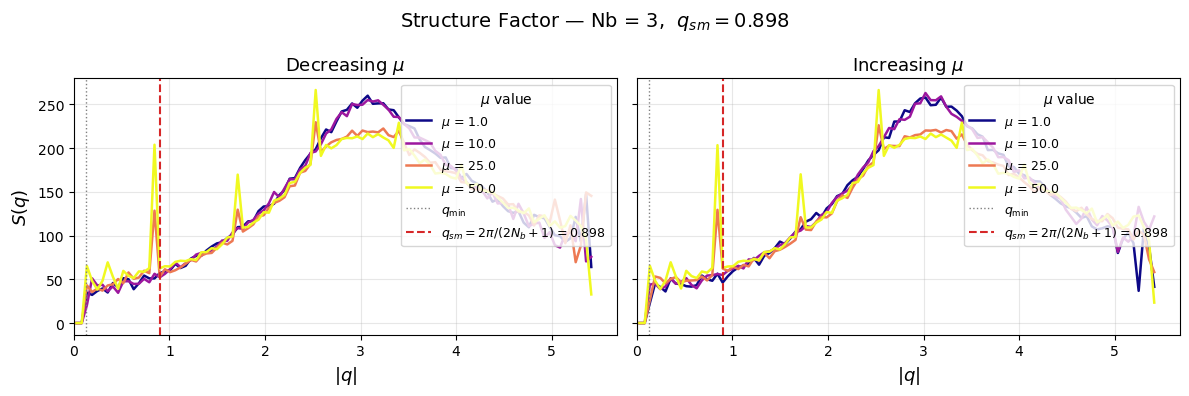

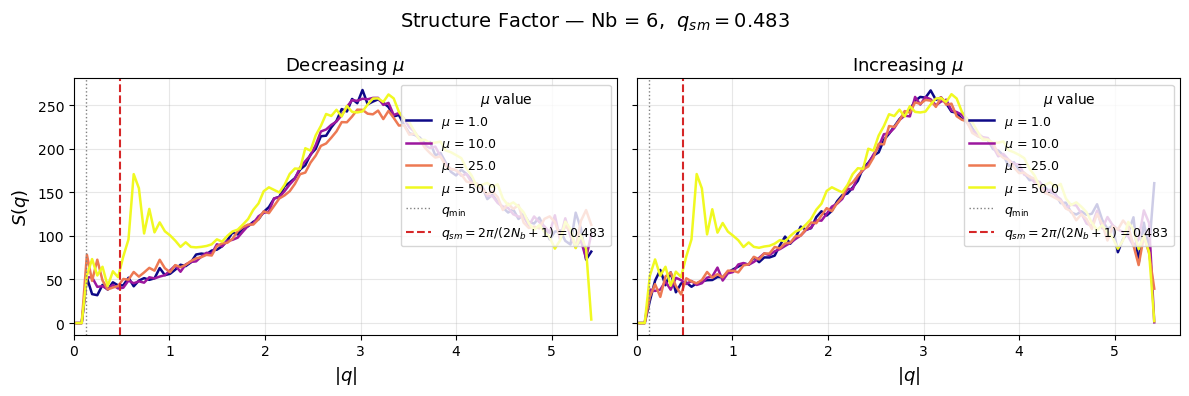

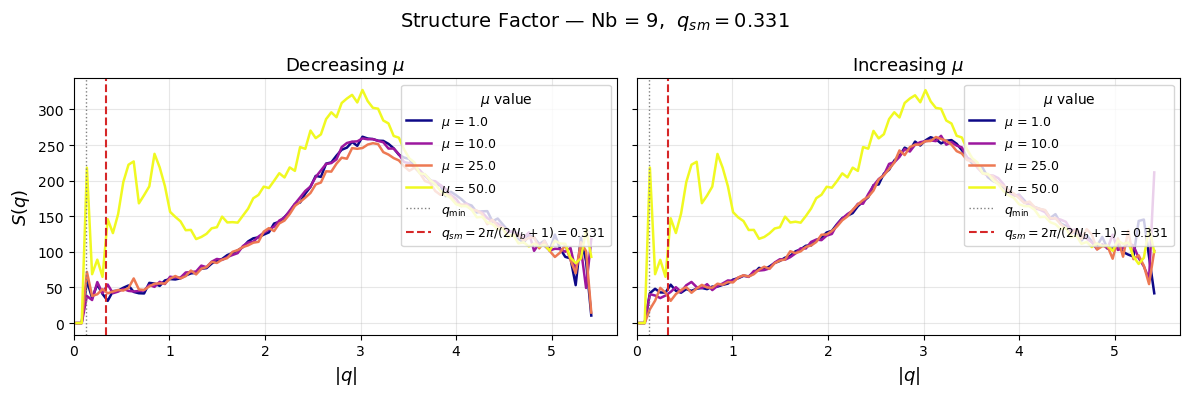

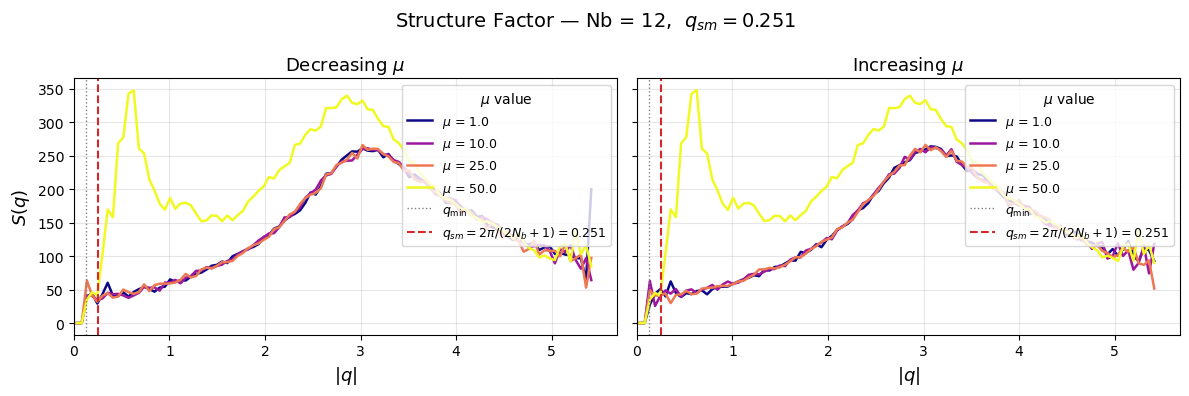

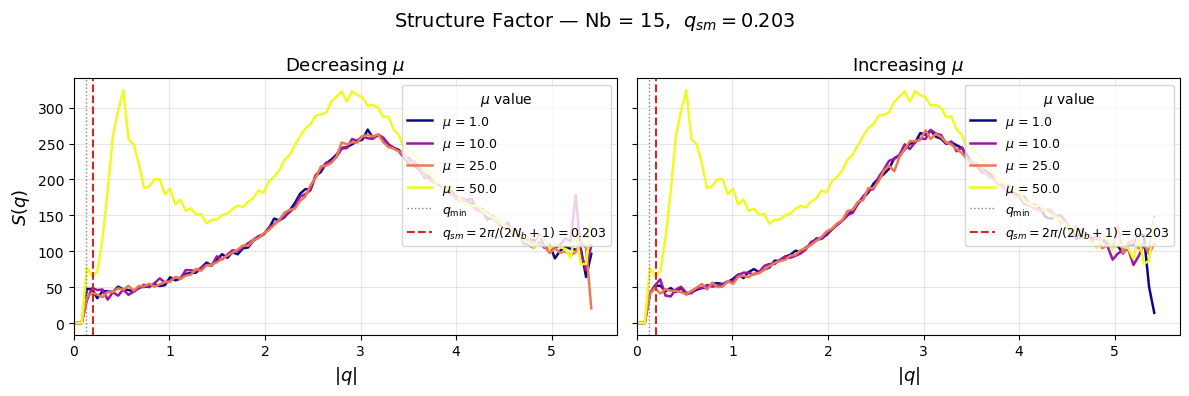

In [27]:
mu_cmap   = plt.cm.get_cmap('plasma', len(TARGET_MU))
mu_colors = {mu: mu_cmap(i) for i, mu in enumerate(TARGET_MU)}

for nb in nb_vals_sk:
    res_by_dir = {r['direction']: r for r in sk_results if r['nb'] == nb}
    directions = sorted(res_by_dir.keys())

    # Expected smectic layering wavevector for this LC length
    q_smectic = 2 * np.pi / (2 * nb + 1)

    fig, axes = plt.subplots(1, len(directions), figsize=(6*len(directions), 4),
                              sharey=True)
    if len(directions) == 1:
        axes = [axes]

    for ax, direction in zip(axes, directions):
        res   = res_by_dir[direction]
        q_min = 2*np.pi / res['L'].min()

        for mu_target in TARGET_MU:
            frame_idx = int(np.argmin(np.abs(res['mu_frames'] - mu_target)))
            actual_mu = res['mu_frames'][frame_idx]
            sk_frame  = res['sk_all'][frame_idx]

            ax.plot(res['k'], sk_frame,
                    color=mu_colors[mu_target], lw=1.8,
                    label=fr"$\mu$ = {actual_mu:.1f}")

        ax.axvline(x=q_min,     color='gray',       ls=':',  lw=1.0,
                   label=r'$q_{\min}$')
        ax.axvline(x=q_smectic, color='tab:red',    ls='--', lw=1.5,
                   label=fr'$q_{{sm}} = 2\pi/(2N_b+1) = {q_smectic:.3f}$')

        ax.set_xlabel(r"$|q|$",                        fontsize=13)
        ax.set_title(direction.capitalize() + r" $\mu$", fontsize=13)
        ax.set_xlim(left=0)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=9, title=r"$\mu$ value", loc='upper right')

    axes[0].set_ylabel(r"$S(q)$", fontsize=13)
    fig.suptitle(fr"Structure Factor — Nb = {nb},  $q_{{sm}} = {q_smectic:.3f}$",
                 fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"sk_vs_mu_nb{nb}.png"), dpi=150)
    plt.show()

### Plot: S(q) evolution as a function of μ — heatmap (one figure per LC length)

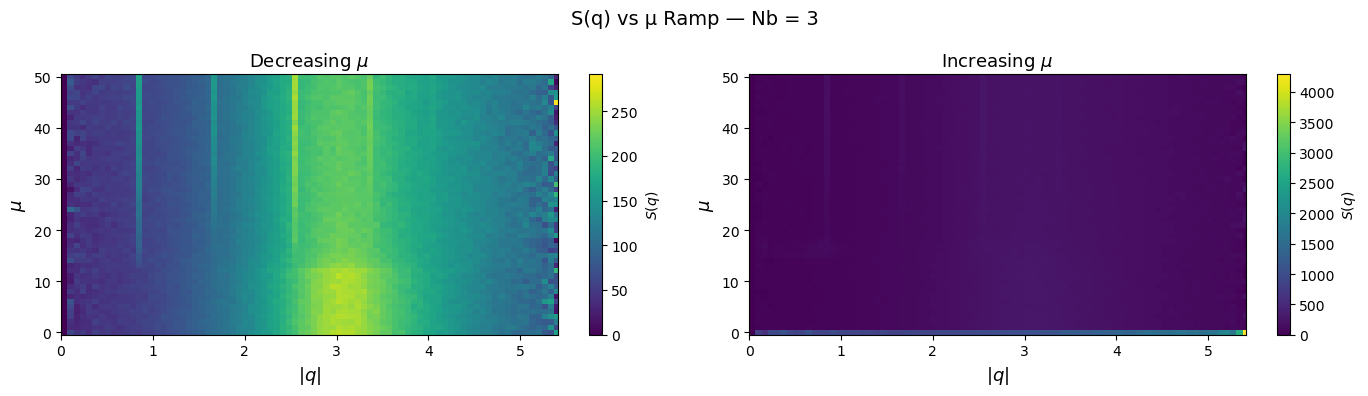

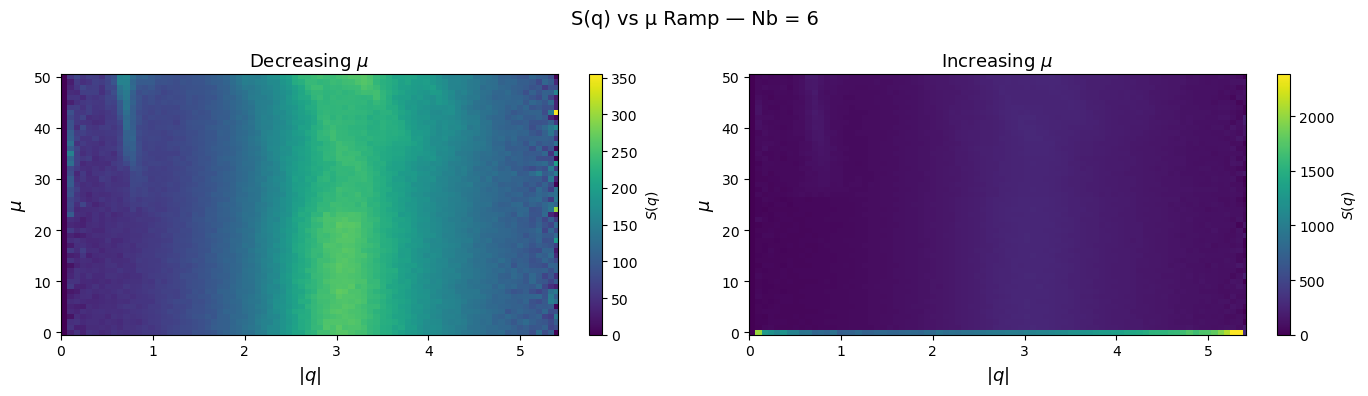

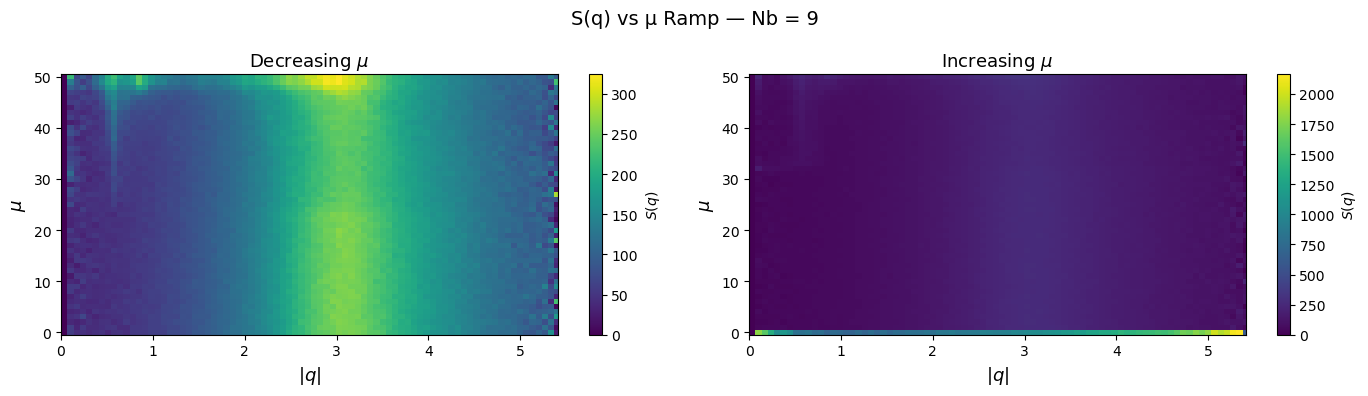

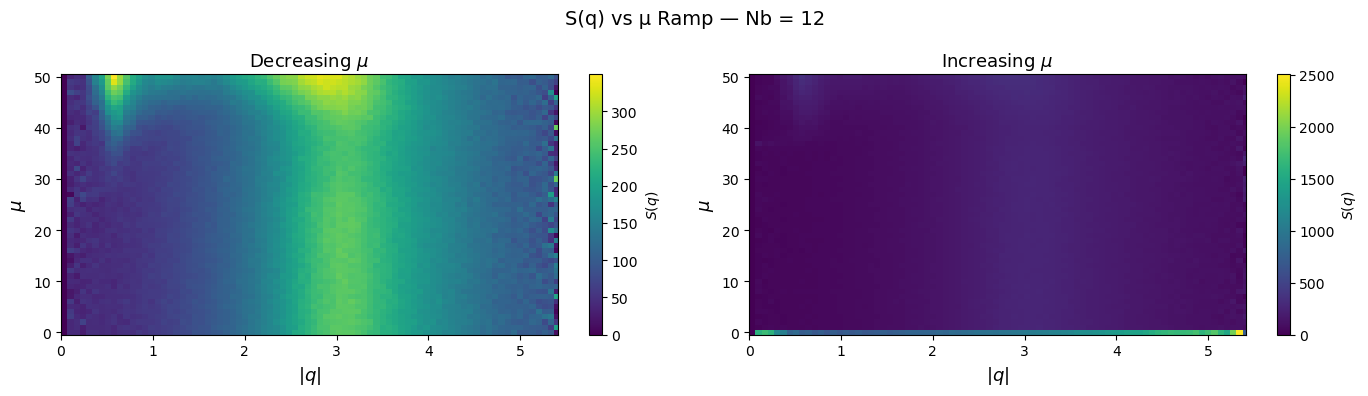

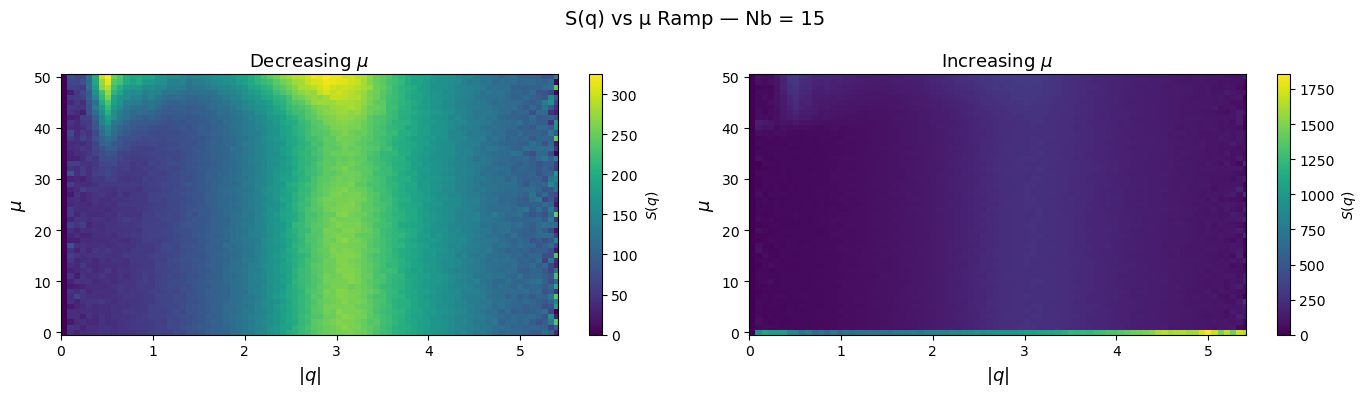

In [21]:
for nb in nb_vals_sk:
    res_by_dir = {r['direction']: r for r in sk_results if r['nb'] == nb}
    directions = sorted(res_by_dir.keys())

    fig, axes = plt.subplots(1, len(directions), figsize=(7*len(directions), 4))
    if len(directions) == 1:
        axes = [axes]

    for ax, direction in zip(axes, directions):
        res    = res_by_dir[direction]
        sk_mat = res['sk_all']     # (nframes, n_bins)
        mu_arr = res['mu_frames']  # (nframes,)
        k_arr  = res['k']          # (n_bins,)

        im = ax.pcolormesh(k_arr, mu_arr, sk_mat,
                           cmap='viridis', shading='auto')
        plt.colorbar(im, ax=ax, label=r"$S(q)$")
        ax.set_xlabel(r"$|q|$",                        fontsize=13)
        ax.set_ylabel(r"$\mu$",                        fontsize=13)
        ax.set_title(direction.capitalize() + r" $\mu$", fontsize=13)
        ax.set_xlim(0, k_arr.max())

    fig.suptitle(f"S(q) vs μ Ramp — Nb = {nb}", fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"sk_heatmap_nb{nb}.png"), dpi=150)
    plt.show()